In [15]:
import sqlite3
import pandas as pd
import plotly.graph_objects as go
import plotly.express as px
from IPython.display import Image, display
# import os
# import psycopg
# from dotenv import load_dotenv

# load_dotenv()

# # Connect to PostgreSQL using environment variables
# conn = psycopg.connect(
#     host=os.getenv("PGHOST"),
#     port=os.getenv("PGPORT"),
#     dbname=os.getenv("PGDATABASE"),
#     user=os.getenv("PGUSER"),
#     password=os.getenv("PGPASSWORD"),
# )

# Replace the following line with the commented above when querying the pgsql database and not SQLite anymore
conn = sqlite3.connect('../data/voyages.sqlite')

In [16]:
def load_table_data(conn: sqlite3.Connection, table_name: str) -> pd.DataFrame:
    """Load all rows from a SQLite table into a pandas DataFrame."""

    # Build the SELECT query.
    query = f"SELECT * FROM {table_name}"

    # Execute the query and let pandas build the DataFrame.
    return pd.read_sql_query(query, conn)


def add_year_month_columns(df: pd.DataFrame, date_column: str, prefix: str = "", drop_col: bool = True) -> pd.DataFrame:
    """Extract the year and month from an ISO-formatted date column."""

    # Convert the column to datetime objects.
    # errors="coerce" turns invalid dates into NaT instead of raising an error.
    dates = pd.to_datetime(df[date_column], errors="coerce")

    # Add the year as an integer column.
    df[f"{prefix}year"] = dates.dt.year

    # Add the month as a two-digit string ("05", not "5").
    df[f"{prefix}month"] = dates.dt.strftime("%m")

    # Remove the given column and return everything
    if drop_col: df.drop(columns=[date_column], inplace=True)

    # Set new columns types to int
    df[f"{prefix}year"] = df[f"{prefix}year"].astype(pd.Int64Dtype())
    df[f"{prefix}month"] = df[f"{prefix}month"].astype(pd.Int64Dtype())

    return df


def convert_to_integer(df: pd.DataFrame, columns: list[str]) -> pd.DataFrame:
    """For each given column, convert columns containing incorrectly formatted integers to integers."""

    for column in columns:
        # Convert values to strings so we can safely manipulate separators.
        values = df[column].astype("string")

        # Remove commas and dots used as thousands separators.
        values = values.str.replace(",", "", regex=False)
        values = values.str.replace(".", "", regex=False)

        # Convert the cleaned values to integers.
        # Invalid values are replaced with NaN instead of raising an error.
        df[column] = pd.to_numeric(values, errors="coerce").astype("Int64")

    return df


def get_details_of_geo_place(geo_place_name: pd.DataFrame) -> tuple[pd.DataFrame]:
    """Get person and cargo arrival/departure details for a geographical place."""

    # Get the primary key of the requested geographical place.
    pk_geo_place = geo_place[geo_place['name'] == geo_place_name]['pk_geogr_place'].iloc[0]

    # Get all steps associated with the geographical place.
    selected_steps: pd.DataFrame = step[step["fk_geo_place"] == pk_geo_place]

    # Join steps with person-related and cargo-related data.
    geo_place_steps_persons = selected_steps.merge(step_persons, how='left', left_on="pk_step", right_on="fk_step")
    geo_place_steps_cargo = selected_steps.merge(step_cargo, how='left', left_on="pk_step", right_on="fk_step_cargo")

    # Select arrival and departure information.
    df_arrival_persons = geo_place_steps_persons[['arrival_date_iso', 'd_1', 'd_2', 'd_3', 'd_4']]
    df_arrival_persons['total_persons'] = df_arrival_persons[['d_1', 'd_2', 'd_3', 'd_4']].sum(axis=1)
    df_departure_persons = geo_place_steps_persons[['departure_date_iso', 'e_1', 'e_2', 'e_3', 'e_4', 'income']]
    df_departure_persons['total_persons'] = df_departure_persons[['e_1', 'e_2', 'e_3', 'e_4']].sum(axis=1)
    df_arrival_cargo = geo_place_steps_cargo[['arrival_date_iso', 'dis_weight_in_tons']]
    df_departure_cargo = geo_place_steps_cargo[['departure_date_iso', 'emb_weight_in_tons', 'income']]

    # Extract year and month from the arrival and departure dates.
    df_arrival_persons = add_year_month_columns(df_arrival_persons, 'arrival_date_iso', '')
    df_departure_persons = add_year_month_columns(df_departure_persons, 'departure_date_iso', '')
    df_arrival_cargo = add_year_month_columns(df_arrival_cargo, 'arrival_date_iso', '')
    df_departure_cargo = add_year_month_columns(df_departure_cargo, 'departure_date_iso', '')

    # Change name of concurrenet columns so that there is no overlap when merging
    df_departure_persons.rename(columns={'income':'income_passenger'}, inplace=True)
    df_departure_cargo.rename(columns={'income':'income_cargo'}, inplace=True)

    # Merge both persons and cargo into one single arrival and departure DataFrame
    df_arrival = pd.merge(df_arrival_persons, df_arrival_cargo, on=['year', 'month'], how="outer")
    df_departure = pd.merge(df_departure_persons, df_departure_cargo, on=['year', 'month'], how="outer")

    return df_arrival, df_departure


def get_globals_steps() -> tuple[pd.DataFrame]:
    """Format, ready for analysis all voyage steps."""

    # Join steps with person-related and cargo-related data.
    step_step_persons = step.merge(step_persons, how='left', left_on="pk_step", right_on="fk_step")
    step_step_cargo = step.merge(step_cargo, how='left', left_on="pk_step", right_on="fk_step_cargo")

    # Select arrival and departure information.
    df_arrival_persons = step_step_persons[['arrival_date_iso', 'd_1', 'd_2', 'd_3', 'd_4']]
    df_arrival_persons['total_persons'] = df_arrival_persons[['d_1', 'd_2', 'd_3', 'd_4']].sum(axis=1)
    df_departure_persons = step_step_persons[['departure_date_iso', 'e_1', 'e_2', 'e_3', 'e_4', 'income']]
    df_departure_persons['total_persons'] = df_departure_persons[['e_1', 'e_2', 'e_3', 'e_4']].sum(axis=1)
    df_arrival_cargo = step_step_cargo[['arrival_date_iso', 'dis_weight_in_tons']]
    df_departure_cargo = step_step_cargo[['departure_date_iso', 'emb_weight_in_tons', 'income']]

    # Extract year and month from the arrival and departure dates.
    df_arrival_persons = add_year_month_columns(df_arrival_persons, 'arrival_date_iso', '')
    df_departure_persons = add_year_month_columns(df_departure_persons, 'departure_date_iso', '')
    df_arrival_cargo = add_year_month_columns(df_arrival_cargo, 'arrival_date_iso', '')
    df_departure_cargo = add_year_month_columns(df_departure_cargo, 'departure_date_iso', '')

    # Change name of concurrenet columns so that there is no overlap when merging
    df_departure_persons.rename(columns={'income':'income_passenger'}, inplace=True)
    df_departure_cargo.rename(columns={'income':'income_cargo'}, inplace=True)

    # Merge both persons and cargo into one single arrival and departure DataFrame
    df_arrival = pd.merge(df_arrival_persons, df_arrival_cargo, on=['year', 'month'], how="outer")
    df_departure = pd.merge(df_departure_persons, df_departure_cargo, on=['year', 'month'], how="outer")

    return df_arrival, df_departure


def get_analysis_df(arrivals: pd.DataFrame, departures: pd.DataFrame) -> tuple[pd.DataFrame]:
    """From a given couple of DataFrames, prepare the same couple, but ready for analysis."""

    # Group everything by the year, and make the sum of columns
    arrivals_years = arrivals.groupby('year').sum()
    departure_years = departures.groupby('year').sum()

    # Create a complete range of years
    # all_years = range(
    #     min(arrivals_years.index.min(), departure_years.index.min()),
    #     max(arrivals_years.index.max(), departure_years.index.max()) + 1
    # )
    # # Fill missing years with zeros
    # arrivals_years = (arrivals_years.reindex(all_years, fill_value=0).rename_axis('year'))
    # departure_years = (departure_years.reindex(all_years, fill_value=0).rename_axis('year'))

    # Reset indexes: put years back in place (as normal columns)
    arrivals_years = arrivals_years.reset_index()
    departure_years = departure_years.reset_index()

    return arrivals_years, departure_years


def get_totals(arrivals: pd.DataFrame, departures: pd.DataFrame) -> dict:
    """Compute totals of given DataFrames."""

    return {
        "arrivals_person": arrivals['total_persons'].sum(),
        "arrivals_cargo": arrivals['dis_weight_in_tons'].sum(),
        "departure_person": departures['total_persons'].sum(),
        "departure_cargo": departures['emb_weight_in_tons'].sum()
    }


def get_group_by_months(arrivals: pd.DataFrame, departures: pd.DataFrame) -> tuple[pd.DataFrame]:
    """Group by column "month" the 2 given DataFrames, and return them correctly formated."""

    arrivals_months = arrivals.groupby('month').sum().reset_index()
    departure_months = departures.groupby('month').sum().reset_index() 

    return arrivals_months, departure_months

In [17]:
# Load all needed table from the Database
geo_place = load_table_data(conn, 'geogr_place')
step = load_table_data(conn, 'step')
step_persons = load_table_data(conn, 'step_persons')
step_cargo = load_table_data(conn, 'step_cargo')

# Because columns are wrongly formated: integer are not really integers in the listed columns: 
# sometimes have a comma or dot mixing up.
step_persons = convert_to_integer(step_persons, ['d_1', 'd_2', 'd_3', 'd_4', 'e_1', 'e_2', 'e_3', 'e_4', 'income'])
step_cargo = convert_to_integer(step_cargo, ['dis_weight_in_tons', 'emb_weight_in_tons', 'income'])

# Get total arrivals and departure for persons and cargos
# totals = get_totals(global_arrivals, global_departures)
# print('Total arrivées personnes: ', totals['arrivals_person'])
# print('Total départs personnes: ', totals['departure_person'])
# print('Total arrivées cargo: ', totals['arrivals_cargo'])
# print('Total départs cargo: ', totals['departure_cargo'])

# Comment les flux de passagers et de marchandises à Beyrouth ont-ils évolué entre 1926 et 1939, et quel rôle avait Beyrouth dans le réseau maritime des Messageries Maritimes ?

In [18]:
# Data of interest (used mutliple times accross the analysis)

# Global data, not filtered by city
global_arrivals, global_departures = get_globals_steps()
begin_year = min(global_arrivals['year'].min(), global_departures['year'].min())
end_year = max(global_arrivals['year'].max(), global_departures['year'].max())

# Beirut
beirut_arrivals, beirut_departures = get_details_of_geo_place('Beirut')
beirut_totals = get_totals(beirut_arrivals, beirut_departures)
beirut_arrivals_year, beirut_departure_year = get_analysis_df(beirut_arrivals, beirut_departures)

# Marseille
marseille_arrivals, marseille_departures = get_details_of_geo_place('Marseille')
marseille_totals = get_totals(marseille_arrivals, marseille_departures)
marseille_arrivals_year, marseille_departure_year = get_analysis_df(marseille_arrivals, marseille_departures)

# Alexandria
alexandria_arrivals, alexandria_departures = get_details_of_geo_place('Alexandria')
alexandria_totals = get_totals(alexandria_arrivals, alexandria_departures)
alexandria_arrivals_year, alexandria_departure_year = get_analysis_df(alexandria_arrivals, alexandria_departures)

## A. Mobilité passagères à l'aller et au retour

### 1. Combien de passagers transitent entre Beyrouth et Marseille et entre Beyrouth et Alexandrie?


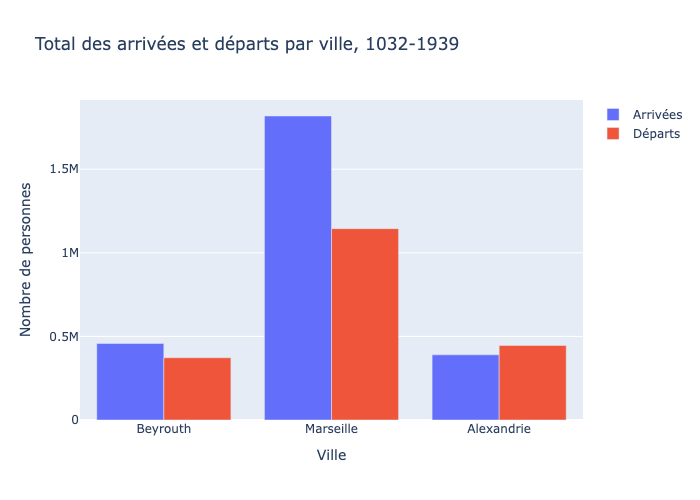

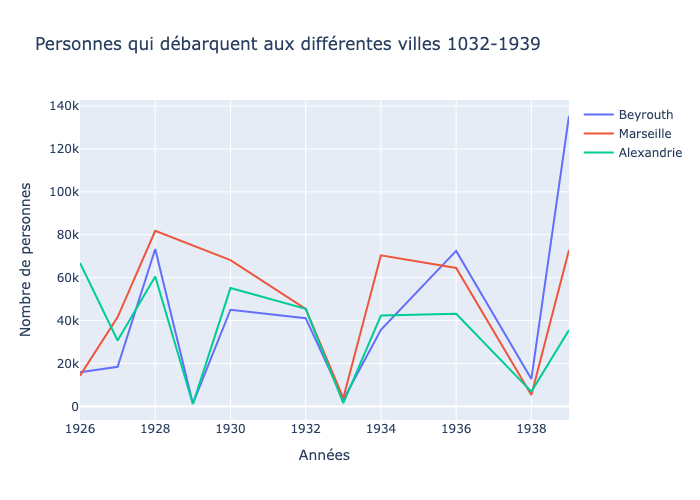

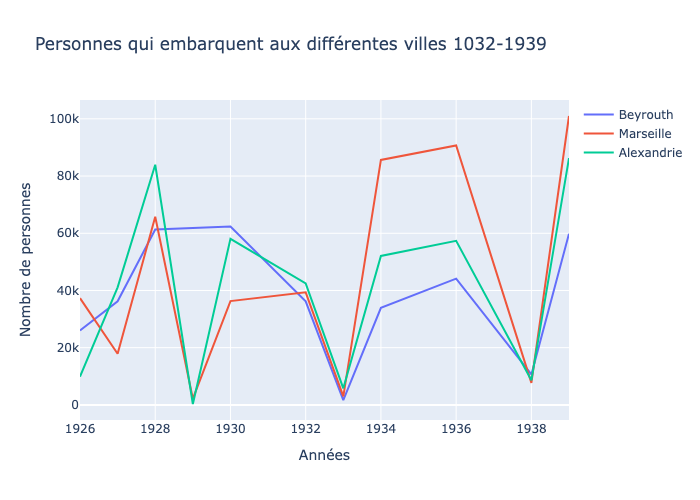

In [19]:
fig = go.Figure()
x = ["Beyrouth", "Marseille", "Alexandrie"]
key = "arrivals_person" # Just to shorten following line
fig.add_trace(go.Bar(x=x, y=[beirut_totals[key], marseille_totals[key], alexandria_totals[key]], name="Arrivées"))
key = "departure_person" # Just to shorten following line
fig.add_trace(go.Bar(x=x, y=[beirut_totals["departure_person"], marseille_totals["departure_person"], alexandria_totals["departure_person"]], name="Départs"))
fig.update_layout(title=f"Total des arrivées et départs par ville, {begin_year}-{end_year}", xaxis_title="Ville", yaxis_title="Nombre de personnes", barmode="group")
fig.write_image("total-arrivals-departures-city.png")
display(Image(filename="total-arrivals-departures-city.png"))

fig = go.Figure()
fig.add_trace(go.Scatter(x=beirut_arrivals_year["year"], y=beirut_arrivals_year["total_persons"], mode="lines", name="Beyrouth"))
fig.add_trace(go.Scatter(x=marseille_arrivals_year["year"], y=marseille_arrivals_year["total_persons"], mode="lines", name="Marseille"))
fig.add_trace(go.Scatter(x=alexandria_arrivals_year["year"], y=alexandria_arrivals_year["total_persons"], mode="lines", name="Alexandrie"))
fig.update_layout(title=f"Personnes qui débarquent aux différentes villes {begin_year}-{end_year}", xaxis_title="Années", yaxis_title="Nombre de personnes")
fig.write_image("persons-arrivals-city.png")
display(Image(filename="persons-arrivals-city.png"))

fig = go.Figure()
fig.add_trace(go.Scatter(x=beirut_departure_year["year"], y=beirut_departure_year["total_persons"], mode="lines", name="Beyrouth"))
fig.add_trace(go.Scatter(x=marseille_departure_year["year"], y=marseille_departure_year["total_persons"], mode="lines", name="Marseille"))
fig.add_trace(go.Scatter(x=alexandria_departure_year["year"], y=alexandria_departure_year["total_persons"], mode="lines", name="Alexandrie"))
fig.update_layout(title=f"Personnes qui embarquent aux différentes villes {begin_year}-{end_year}", xaxis_title="Années", yaxis_title="Nombre de personnes")
fig.write_image("persons-departures-city.png")
display(Image(filename="persons-departures-city.png"))

### 2. Comment les passagers sont-ils répartis entre les différentes classes de voyage entre 1926 et 1939 ?

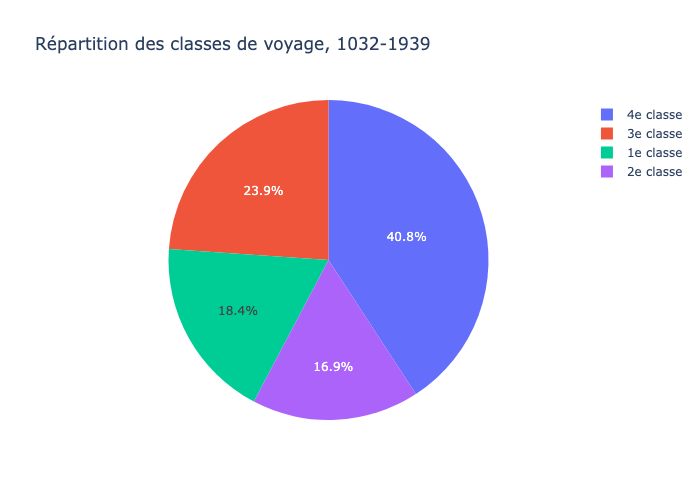

In [20]:
fig = px.pie(
    names=['1e classe', '2e classe', '3e classe', '4e classe'],
    values=[global_departures['e_1'].sum(), global_departures['e_2'].sum(), global_departures['e_3'].sum(), global_departures['e_4'].sum()],
    title=f"Répartition des classes de voyage, {begin_year}-{end_year}"
)
fig.write_image("persons-classes.png")
display(Image(filename="persons-classes.png"))

### 3. Beyrouth est-il davantage un port d’embarquement ou de débarquement pour les voyageurs à destination ou en provenance de Marseille et d’Alexandrie ?

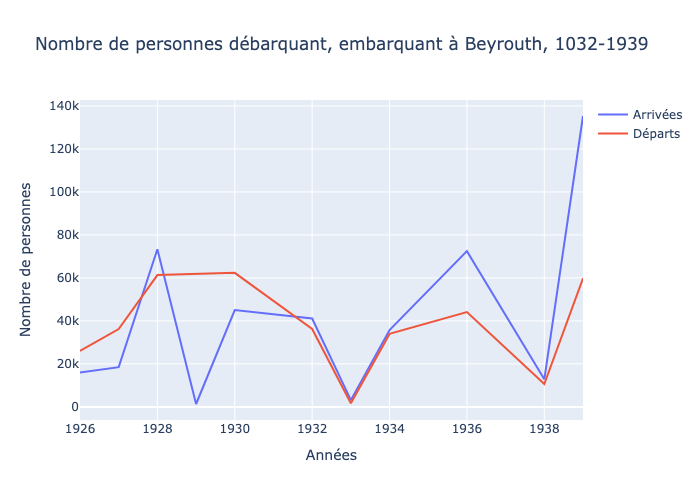

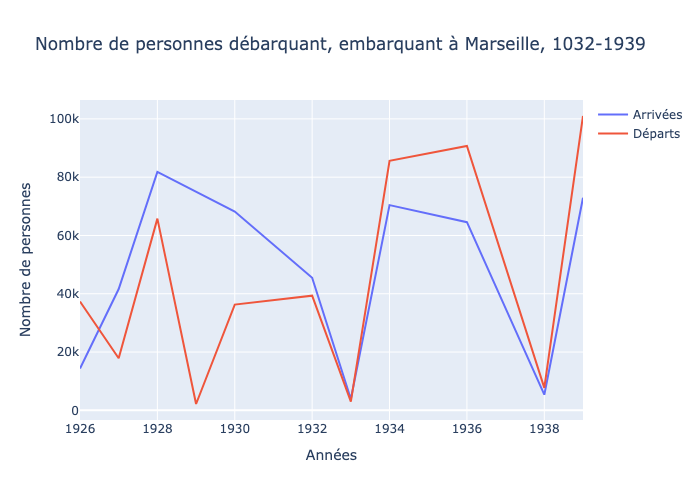

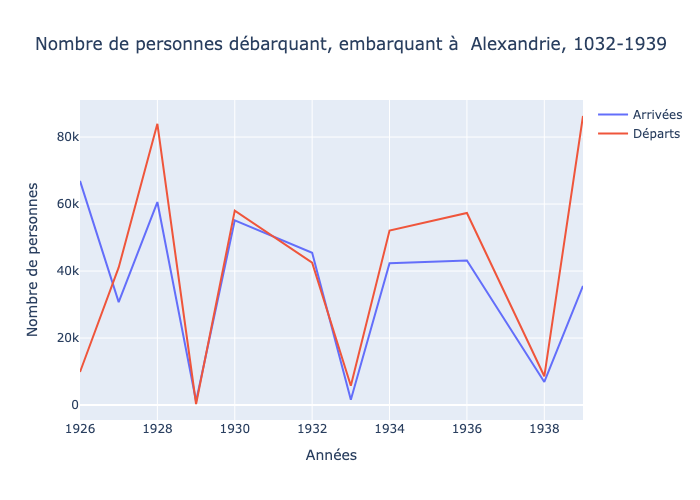

In [21]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=beirut_arrivals_year["year"], y=beirut_arrivals_year["total_persons"], mode="lines", name="Arrivées"))
fig.add_trace(go.Scatter(x=beirut_departure_year["year"], y=beirut_departure_year["total_persons"], mode="lines", name="Départs"))
fig.update_layout(title=f"Nombre de personnes débarquant, embarquant à Beyrouth, {begin_year}-{end_year}", xaxis_title="Années", yaxis_title="Nombre de personnes")
fig.write_image("beirut-persons.png")
display(Image(filename="beirut-persons.png"))

fig = go.Figure()
fig.add_trace(go.Scatter(x=marseille_arrivals_year["year"], y=marseille_arrivals_year["total_persons"], mode="lines", name="Arrivées"))
fig.add_trace(go.Scatter(x=marseille_departure_year["year"], y=marseille_departure_year["total_persons"], mode="lines", name="Départs"))
fig.update_layout(title=f"Nombre de personnes débarquant, embarquant à Marseille, {begin_year}-{end_year}", xaxis_title="Années", yaxis_title="Nombre de personnes")
fig.write_image("marseille-persons.png")
display(Image(filename="marseille-persons.png"))


fig = go.Figure()
fig.add_trace(go.Scatter(x=alexandria_arrivals_year["year"], y=alexandria_arrivals_year["total_persons"], mode="lines", name="Arrivées"))
fig.add_trace(go.Scatter(x=alexandria_departure_year["year"], y=alexandria_departure_year["total_persons"], mode="lines", name="Départs"))
fig.update_layout(title=f"Nombre de personnes débarquant, embarquant à  Alexandrie, {begin_year}-{end_year}", xaxis_title="Années", yaxis_title="Nombre de personnes")
fig.write_image("alexandrie-persons.png")
display(Image(filename="alexandrie-persons.png"))

### 4. Comment évoluent les recettes du transport de passagers générées à Beyrouth ?

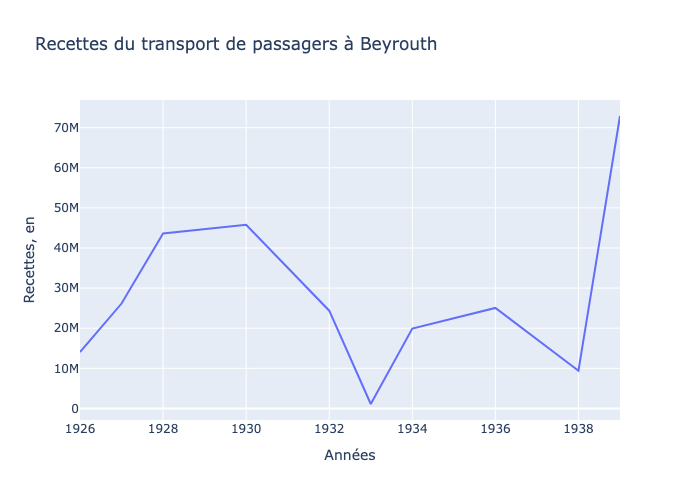

In [22]:
fig = px.line(
    beirut_departure_year,
    x="year",
    y="income_passenger",
    title="Recettes du transport de passagers à Beyrouth",
    labels={
        "year": "Années",
        "income_passenger": "Recettes, en",
    },
)
fig.write_image("beirut-persons-income.png")
display(Image(filename="beirut-persons-income.png"))

## B. Mobilité des marchandises à l'aller et au retour

### 1. Quelle quantité de marchandises est transportée chaque année entre Beyrouth et Marseille et entre Beyrouth et Alexandrie a l’aller et au retour ?

Attention, l'on ne peut savoir dans l'état actuel des choses d'ou viennent les voyageurs à coup sur, pour cela il faudrait savoir leur lieu d'embarquement, pour chacun.

Dans la base de données, il n'y a pas la notion d'aller/retour ; pour une marchandise/personne qui embarque, il s'agit toujours d'aller, sauf si l'on connait l'identité des personnes/marchandise et qu'on peut déterminer les retours ?

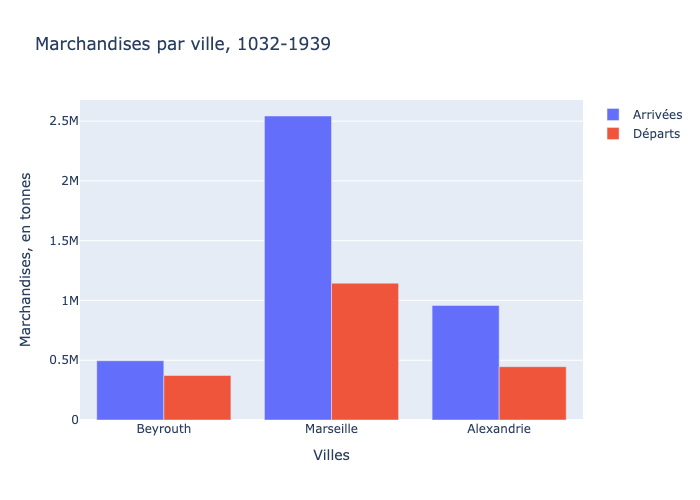

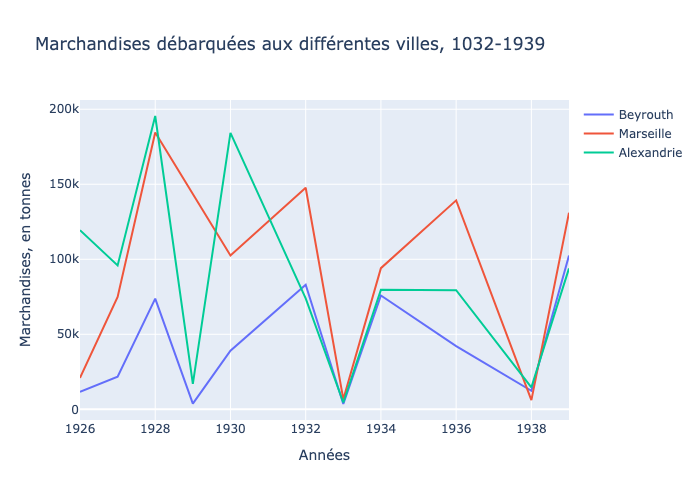

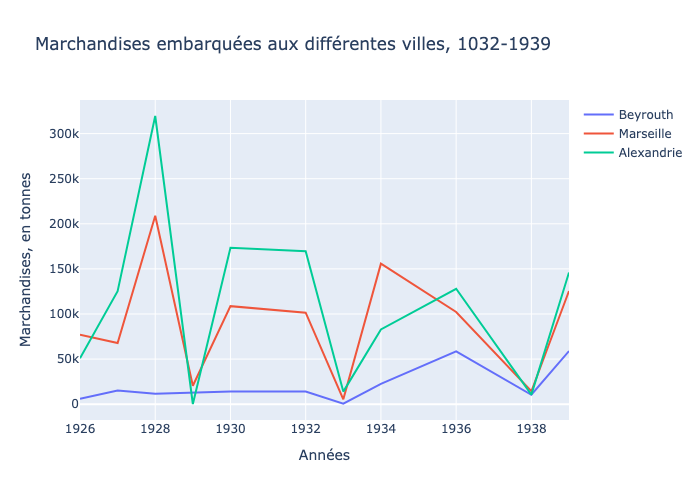

In [23]:
# Create the grouped bar chart
fig = go.Figure()
x = ["Beyrouth", "Marseille", "Alexandrie"]
key = "arrivals_cargo" # Just to shorten following line
fig.add_trace(go.Bar(x=x, y=[beirut_totals[key], marseille_totals[key], alexandria_totals[key]], name="Arrivées"))
key = "departure_cargo" # Just to shorten following line
fig.add_trace(go.Bar(x=x, y=[beirut_totals["departure_person"], marseille_totals["departure_person"], alexandria_totals["departure_person"]], name="Départs"))
fig.update_layout(title=f"Marchandises par ville, {begin_year}-{end_year}", xaxis_title="Villes", yaxis_title="Marchandises, en tonnes", barmode="group")
fig.write_image("cargo-city.png")
display(Image(filename="cargo-city.png"))

fig = go.Figure()
fig.add_trace(go.Scatter(x=beirut_arrivals_year["year"], y=beirut_arrivals_year["dis_weight_in_tons"], mode="lines", name="Beyrouth"))
fig.add_trace(go.Scatter(x=marseille_arrivals_year["year"], y=marseille_arrivals_year["dis_weight_in_tons"], mode="lines", name="Marseille"))
fig.add_trace(go.Scatter(x=alexandria_arrivals_year["year"], y=alexandria_arrivals_year["dis_weight_in_tons"], mode="lines", name="Alexandrie"))
fig.update_layout(title=f"Marchandises débarquées aux différentes villes, {begin_year}-{end_year}", xaxis_title="Années", yaxis_title="Marchandises, en tonnes")
fig.write_image("cargo-arrivals-city.png")
display(Image(filename="cargo-arrivals-city.png"))

fig = go.Figure()
fig.add_trace(go.Scatter(x=beirut_departure_year["year"], y=beirut_departure_year["emb_weight_in_tons"], mode="lines", name="Beyrouth"))
fig.add_trace(go.Scatter(x=marseille_departure_year["year"], y=marseille_departure_year["emb_weight_in_tons"], mode="lines", name="Marseille"))
fig.add_trace(go.Scatter(x=alexandria_departure_year["year"], y=alexandria_departure_year["emb_weight_in_tons"], mode="lines", name="Alexandrie"))
fig.update_layout(title=f"Marchandises embarquées aux différentes villes, {begin_year}-{end_year}", xaxis_title="Années", yaxis_title="Marchandises, en tonnes")
fig.write_image("cargo-departure-city.png")
display(Image(filename="cargo-departure-city.png"))

### 2. Beyrouth apparaît-il principalement comme un port d’importation ou d’exportation de marchandises entre 1926 et 1939 à l’aller et au retour ?

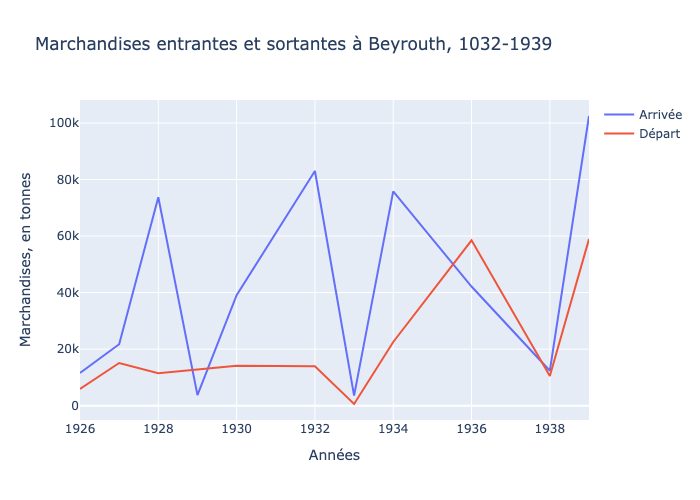

In [24]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=beirut_arrivals_year["year"], y=beirut_arrivals_year["dis_weight_in_tons"], mode="lines", name="Arrivée"))
fig.add_trace(go.Scatter(x=beirut_departure_year["year"], y=beirut_departure_year["emb_weight_in_tons"], mode="lines", name="Départ"))
fig.update_layout(title=f"Marchandises entrantes et sortantes à Beyrouth, {begin_year}-{end_year}", xaxis_title="Années", yaxis_title="Marchandises, en tonnes")
fig.write_image("beirut-cargo.png")
display(Image(filename="beirut-cargo.png"))

### 3. Comment évoluent les recettes du transport de marchandises générées à Beyrouth à l’aller et au retour ?

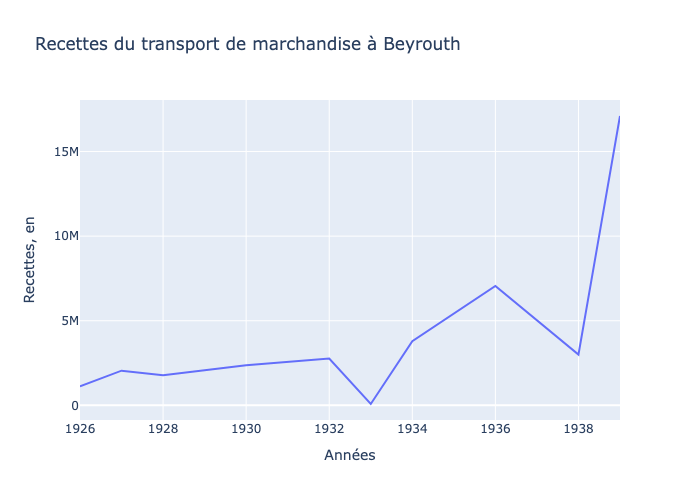

In [25]:
fig = px.line(
    beirut_departure_year,
    x="year",
    y="income_cargo",
    title="Recettes du transport de marchandise à Beyrouth",
    labels={
        "year": "Années",
        "income_cargo": "Recettes, en",
    },
)
fig.write_image("beirut-cargo-income.png")
display(Image(filename="beirut-cargo-income.png"))

## C. Quelle est la contribution respective du transport de passagers et du transport de marchandises aux recettes générées à Beyrouth entre 1926 et 1939 ?

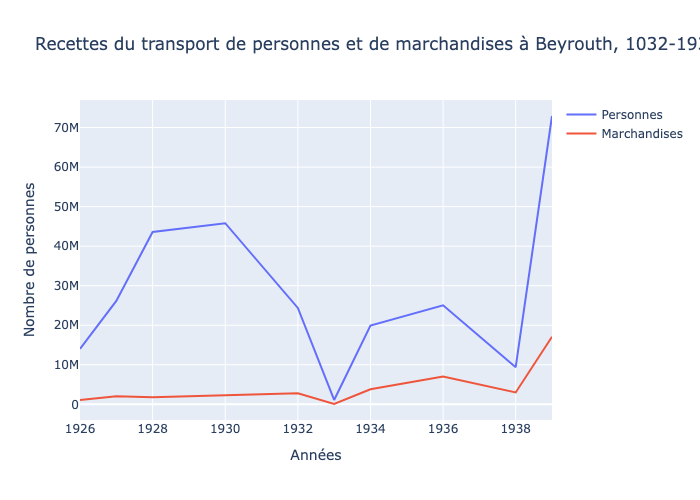

In [26]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=beirut_departure_year["year"], y=beirut_departure_year["income_passenger"], mode="lines", name="Personnes"))
fig.add_trace(go.Scatter(x=beirut_departure_year["year"], y=beirut_departure_year["income_cargo"], mode="lines", name="Marchandises"))
fig.update_layout(title=f"Recettes du transport de personnes et de marchandises à Beyrouth, {begin_year}-{end_year}", xaxis_title="Années", yaxis_title="Nombre de personnes")
fig.write_image("beirut-person-cargo.png")
display(Image(filename="beirut-person-cargo.png"))

## D. Evenements extérieurs Comment la crise économique de 1929 a-t-elle affecté les flux de passagers et de marchandises à destination et en provenance de Beyrouth à l’aller et au retour ?

...

## E. Comment l’inauguration du port de Haïfa en 1933 a-t-elle affecté les flux de passagers et de marchandises à destination et en provenance de Beyrouth ? Dans quelle mesure ces transformations ont-elles modifié la position de Beyrouth dans les réseaux maritimes régionaux et méditerranéens ?

...

## F. Comment la saisonnalité influence-t-elle les flux de passagers et de marchandises dans le port de Beyrouth durant l’entre-deux-guerres ? Les flux de passagers et de marchandises se concentrent-ils à certains mois ? La saisonnalité des passagers et des marchandises suit-elle le même rythme ? Le schéma saisonnier change-t-il pendant la crise de 1929 ou après 1933 ?

In [27]:
# Group everything by the month, and make the sum of columns
beirut_arrivals_months_all, beirut_departure_months_all = get_group_by_months(beirut_arrivals, beirut_departures)
beirut_arrivals_months_1929, beirut_departure_months_1929 = get_group_by_months(beirut_arrivals[beirut_arrivals['year'] == 1929], beirut_departures[beirut_departures['year'] == 1929])
beirut_arrivals_months_after_1933, beirut_departure_months_after_1933 = get_group_by_months(beirut_arrivals[beirut_arrivals['year'] > 1933], beirut_departures[beirut_departures['year'] > 1933])
beirut_arrivals_months_before_1933, beirut_departure_months_before_1933 = get_group_by_months(beirut_arrivals[beirut_arrivals['year'] < 1933], beirut_departures[beirut_departures['year'] < 1933])

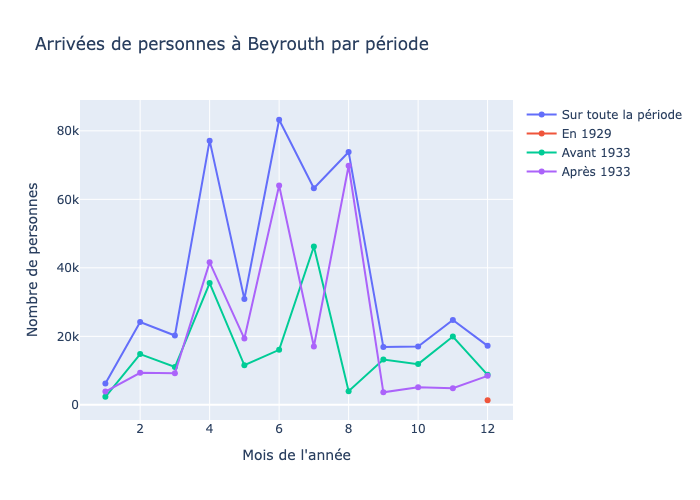

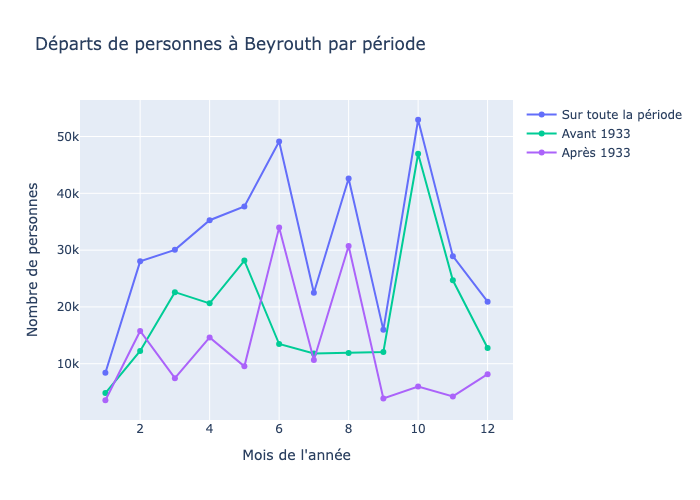

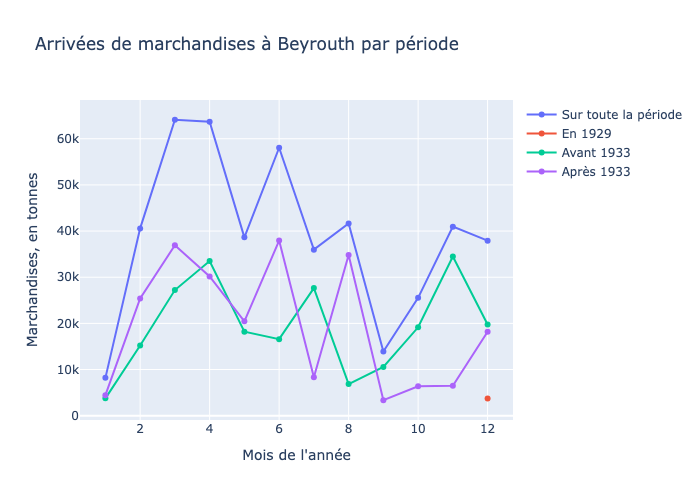

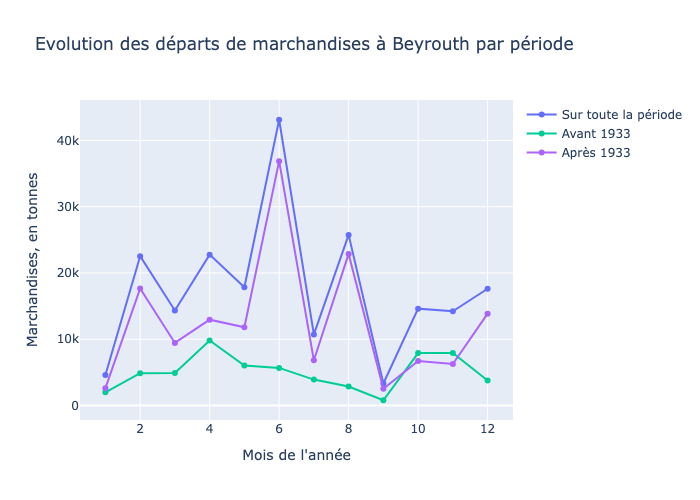

In [28]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=beirut_arrivals_months_all['month'], y=beirut_arrivals_months_all['total_persons'], name="Sur toute la période"))
fig.add_trace(go.Scatter(x=beirut_arrivals_months_1929['month'], y=beirut_arrivals_months_1929['total_persons'], name="En 1929"))
fig.add_trace(go.Scatter(x=beirut_arrivals_months_before_1933['month'], y=beirut_arrivals_months_before_1933['total_persons'], name="Avant 1933"))
fig.add_trace(go.Scatter(x=beirut_arrivals_months_after_1933['month'], y=beirut_arrivals_months_after_1933['total_persons'], name="Après 1933"))
fig.update_layout(title="Arrivées de personnes à Beyrouth par période", xaxis_title="Mois de l'année", yaxis_title="Nombre de personnes", barmode="group")
fig.write_image("beirut-persons-arrivals-periods-months.png")
display(Image(filename="beirut-persons-arrivals-periods-months.png"))

fig = go.Figure()
fig.add_trace(go.Scatter(x=beirut_departure_months_all['month'], y=beirut_departure_months_all['total_persons'], name="Sur toute la période"))
fig.add_trace(go.Scatter(x=beirut_departure_months_1929['month'], y=beirut_departure_months_1929['total_persons'], name="En 1929"))
fig.add_trace(go.Scatter(x=beirut_departure_months_before_1933['month'], y=beirut_departure_months_before_1933['total_persons'], name="Avant 1933"))
fig.add_trace(go.Scatter(x=beirut_departure_months_after_1933['month'], y=beirut_departure_months_after_1933['total_persons'], name="Après 1933"))
fig.update_layout(title="Départs de personnes à Beyrouth par période", xaxis_title="Mois de l'année", yaxis_title="Nombre de personnes", barmode="group")
fig.write_image("beirut-persons-departures-periods-months.png")
display(Image(filename="beirut-persons-departures-periods-months.png"))

fig = go.Figure()
fig.add_trace(go.Scatter(x=beirut_arrivals_months_all['month'], y=beirut_arrivals_months_all['dis_weight_in_tons'], name="Sur toute la période"))
fig.add_trace(go.Scatter(x=beirut_arrivals_months_1929['month'], y=beirut_arrivals_months_1929['dis_weight_in_tons'], name="En 1929"))
fig.add_trace(go.Scatter(x=beirut_arrivals_months_before_1933['month'], y=beirut_arrivals_months_before_1933['dis_weight_in_tons'], name="Avant 1933"))
fig.add_trace(go.Scatter(x=beirut_arrivals_months_after_1933['month'], y=beirut_arrivals_months_after_1933['dis_weight_in_tons'], name="Après 1933"))
fig.update_layout(title="Arrivées de marchandises à Beyrouth par période", xaxis_title="Mois de l'année", yaxis_title="Marchandises, en tonnes", barmode="group")
fig.write_image("beirut-cargo-arrivals-periods-months.png")
display(Image(filename="beirut-cargo-arrivals-periods-months.png"))

fig = go.Figure()
fig.add_trace(go.Scatter(x=beirut_departure_months_all['month'], y=beirut_departure_months_all['emb_weight_in_tons'], name="Sur toute la période"))
fig.add_trace(go.Scatter(x=beirut_departure_months_1929['month'], y=beirut_departure_months_1929['emb_weight_in_tons'], name="En 1929"))
fig.add_trace(go.Scatter(x=beirut_departure_months_before_1933['month'], y=beirut_departure_months_before_1933['emb_weight_in_tons'], name="Avant 1933"))
fig.add_trace(go.Scatter(x=beirut_departure_months_after_1933['month'], y=beirut_departure_months_after_1933['emb_weight_in_tons'], name="Après 1933"))
fig.update_layout(title="Evolution des départs de marchandises à Beyrouth par période", xaxis_title="Mois de l'année", yaxis_title="Marchandises, en tonnes", barmode="group")
fig.write_image("beirut-cargo-departures-periods-months.png")
display(Image(filename="beirut-cargo-departures-periods-months.png"))